# Resting-state tuning — 400 E / 100 I HH network, beta bump

Revision of `hh_400E_100I_gmax_gates_rest_tuning`. Equations are unchanged except for one
addition (`PHI_I`). What changed and why:

| # | Change | Reason |
|---|---|---|
| 1 | network wrapped in `build_net(...)` | the old version was module-level globals in one cell, so nothing could be swept |
| 2 | `spectrum()` fits and removes the aperiodic 1/f component | `argmax(pxx)` over 5–100 Hz returns the top of the 1/f slope, not a rhythm. The old "12.5 Hz peak" is almost certainly that artifact of the metric |
| 3 | `SIM_TIME` 3 s → 40 s, PSDs averaged over seeds | 2.5 s with a 2 s window is one Welch segment: ~5.6 dB scatter per bin, larger than the bump being looked for |
| 4 | I rate raised via **drive** (`I_tonic_I`), refractory 2 → 1 ms. `phi_I` exists but defaults to 1 | I was firing *slower* than E (2.59 vs 4.87 Hz), which is backwards. See the warning below — the Wang–Buzsáki temperature factor does **not** transplant onto your conductances |
| 5 | `TAU_GABA_DECAY` 8 → 16 ms, I delays 2–5 → 4–8 ms | loop half-period was ~13.5 ms → rings at 35–40 Hz (gamma). Beta at 20–25 Hz needs ~22 ms |
| 6 | `w_IE` and `P_IE` raised | frequency and prominence are separate knobs; gain sets bump height |
| 7 | `M_LFP` records every 4th E cell | `record=True` on 400 cells × 3 vars at 0.5 ms is ~600 MB for a 40 s run |
| 8 | `cpp_standalone` backend | makes multi-seed 40 s sweeps affordable |

**On the 1/f.** Nothing here involves DBS. The Poisson background drives asynchronous spiking,
and every spike is filtered through the AMPA/GABA kernels, which are low-pass. So the summed
synaptic current falls off as roughly 1/f^a with no stimulation anywhere in the model. A "beta
band" is a *bump on top of that slope*, not a standalone peak — which is why it has to be
measured as prominence above a fitted aperiodic component.

**`phi_I` warning — measured, not assumed.** The Wang–Buzsáki fast-spiking trick is a
temperature factor `phi` on the h and n gates. Applied to *your* conductance set (`G_NA = 24 uS`,
`G_K = 7.2 uS`, `E_L = -54.4 mV`) it **silences the I cells completely** — `phi_I = 3` and
`phi_I = 5` both give I = 0.00 Hz at every tonic drive tested from 0.35 to 1.6 nA. Faster n and h
kinetics cut the spike short before threshold is reached. Wang–Buzsáki's phi = 5 goes with
*their* conductances (g_Na 35, g_K 9 mS/cm², E_L −65 mV, instantaneous m); the factor alone is
not portable. So `phi_I` defaults to 1 here and the I rate is raised with drive instead. If you
want a true fast-spiking phenotype, port the whole WB conductance set, not just phi.

**Drive and gain are coupled.** Inhibition onto E scales as `rate_I x w_IE x P_IE`. Raising
`I_tonic_I` to get I to 11 Hz while also raising `w_IE` to 6 and `P_IE` to 0.20 multiplies the
inhibitory drive onto E by ~17x and collapses E to 0.3 Hz — measured. Raise the I rate first with
`w_IE` and `P_IE` at their original values, then tune gain in §6.

**Order to work through this.** Run §3 first with the old settings
(`tau_gaba_decay=8, phi_I=1`) — §2's metric may reveal a bump that was already there. Then turn
on the I-cell fix (§4), which moves where every other parameter needs to sit. Only then sweep
`τ_GABA` (§5) and gain (§6).

Set `QUICK = False` for the real runs. `QUICK = True` uses 6 s and one seed so the notebook
executes in a couple of minutes; the numbers it produces are not publication-grade.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from brian2 import *
from scipy import signal    # after brian2: `from brian2 import *` shadows the
                            # name `signal` with the stdlib module in Brian 2.10

QUICK = True

prefs.devices.cpp_standalone.extra_make_args_unix = ['-j4']
set_device('cpp_standalone', directory='/tmp/hh_rest_build', build_on_run=True)
BrianLogger.suppress_name('resolution_conflict', 'method_choice')

DT      = 0.02*ms
REC_DT  = 0.5*ms
FS_LFP  = 1.0/float(REC_DT/second)

SIM_TIME = (6 if QUICK else 40)*second
DISCARD  = 1.0*second
SEEDS    = (1,) if QUICK else (1, 2, 3)

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9,
                     'axes.grid': True, 'grid.alpha': 0.25})
print(f'SIM_TIME = {SIM_TIME}, seeds = {SEEDS}, LFP fs = {FS_LFP:.0f} Hz')

SIM_TIME = 6. s, seeds = (1,), LFP fs = 2000 Hz


## 1. `build_net` — change 1

Same equations as before. Everything that needs sweeping is now an argument with the old value
as its default, except `tau_gaba_decay`, `phi_I`, `w_IE`, `P_IE` and the I delays, whose
defaults are the new recommended values. Pass the old ones explicitly to reproduce the previous
behaviour:

```python
build_net(tau_gaba_decay=8.0, phi_I=1.0, w_IE=3.0, P_IE=0.10,
          delay_I=(2.0, 5.0), refractory_I=2.0)
```

In [ ]:
def gate_jump_norm(tau_rise, tau_decay):
    # Gate dynamics:
    #   dx/dt = -x/tau_rise
    #   ds/dt = -s/tau_decay + x/tau_rise
    #
    # Return a jump normalization so w=1 gives peak(s) ~= 1.
    tr = float(tau_rise/ms)
    td = float(tau_decay/ms)
    t_peak = tr*td/(td-tr) * np.log(td/tr)
    peak = td/(td-tr) * (np.exp(-t_peak/td) - np.exp(-t_peak/tr))
    return 1.0/peak


EQS_TEMPLATE = r"""
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + I_AMPA_ext
    + I_AMPA_rec
    + I_GABA_rec
    + I_tonic
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = PHI*(alpha_h*(1-h) - beta_h*h) : 1
dn/dt = PHI*(alpha_n*(1-n) - beta_n*n) : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dx_AMPA_ext/dt = -x_AMPA_ext/TAU_AMPA_RISE : 1
ds_AMPA_ext/dt = -s_AMPA_ext/TAU_AMPA_DECAY + x_AMPA_ext/TAU_AMPA_RISE : 1

dx_AMPA_rec/dt = -x_AMPA_rec/TAU_AMPA_RISE : 1
ds_AMPA_rec/dt = -s_AMPA_rec/TAU_AMPA_DECAY + x_AMPA_rec/TAU_AMPA_RISE : 1

dx_GABA_rec/dt = -x_GABA_rec/TAU_GABA_RISE : 1
ds_GABA_rec/dt = -s_GABA_rec/TAU_GABA_DECAY + x_GABA_rec/TAU_GABA_RISE : 1

I_AMPA_ext = G_AMPA_EXT * s_AMPA_ext * (E_AMPA-v) : amp
I_AMPA_rec = G_AMPA_REC * s_AMPA_rec * (E_AMPA-v) : amp
I_GABA_rec = G_GABA_REC * s_GABA_rec * (E_GABA-v) : amp

I_tonic : amp
"""


def build_net(
        # --- change 5: loop timescale ---
        tau_gaba_decay=16.0,          # ms   (was 8)
        delay_I=(2.0, 4.0),           # ms   I->E and I->I (was 2-5)
        delay_E=(1.0, 3.0),           # ms   E->E and E->I
        # --- change 4: I-cell rate ---
        phi_I=1.0,                    #      >2 silences these cells; see the warning
        refractory_I=1.0,             # ms   (was 2)
        # --- change 6: loop gain (start at the original values) ---
        w_IE=3.0,
        P_IE=0.10,
        w_EE=5.0, w_EI=9.0, w_II=1.5,
        P_EE=0.10, P_EI=0.10, P_II=0.10,
        # --- drive (change 4: I raised, E follows) ---
        I_tonic_E=0.35, I_tonic_I=0.70,      # nA  (I was 0.35)
        rate_ext_E=5.0, rate_ext_I=5.0,      # Hz
        w_ext_E=0.625, w_ext_I=0.68,
        N_ext_E=300, N_ext_I=300,
        # --- size / bookkeeping ---
        NE=400, NI=100, seed_val=2,
        lfp_stride=4,                 # change 7
        chosen_E=200):
    """Assemble the resting network. Returns a dict of handles; nothing is run."""
    device.reinit()
    device.activate(directory='/tmp/hh_rest_build', build_on_run=True)
    start_scope()
    seed(seed_val)
    rng = np.random.default_rng(seed_val)
    defaultclock.dt = DT

    CM   = 200*pF
    G_NA = 24*uS
    G_K  = 7.2*uS
    G_L  = 60*nS
    E_NA = 50*mV
    E_K  = -77*mV
    E_L  = -54.4*mV
    E_AMPA = 0*mV
    E_GABA = -80*mV

    TAU_AMPA_RISE  = 0.5*ms
    TAU_AMPA_DECAY = 2.0*ms
    TAU_GABA_RISE  = 0.5*ms
    TAU_GABA_DECAY = tau_gaba_decay*ms

    AMPA_NORM = gate_jump_norm(TAU_AMPA_RISE, TAU_AMPA_DECAY)
    GABA_NORM = gate_jump_norm(TAU_GABA_RISE, TAU_GABA_DECAY)

    g_AMPA_ext_E = 2.08*nS
    g_AMPA_ext_I = 1.62*nS
    g_AMPA_rec_E = 0.104*nS * 800/NE
    g_AMPA_rec_I = 0.081*nS * 800/NE
    g_GABA_E     = 1.25*nS * 200/NI
    g_GABA_I     = 0.973*nS * 200/NI

    common = dict(CM=CM, G_NA=G_NA, G_K=G_K, G_L=G_L, E_NA=E_NA, E_K=E_K, E_L=E_L,
                  E_AMPA=E_AMPA, E_GABA=E_GABA,
                  TAU_AMPA_RISE=TAU_AMPA_RISE, TAU_AMPA_DECAY=TAU_AMPA_DECAY,
                  TAU_GABA_RISE=TAU_GABA_RISE, TAU_GABA_DECAY=TAU_GABA_DECAY)

    ns_E = dict(common, G_AMPA_EXT=g_AMPA_ext_E, G_AMPA_REC=g_AMPA_rec_E,
                G_GABA_REC=g_GABA_E, PHI=1.0)
    ns_I = dict(common, G_AMPA_EXT=g_AMPA_ext_I, G_AMPA_REC=g_AMPA_rec_I,
                G_GABA_REC=g_GABA_I, PHI=phi_I)

    E = NeuronGroup(NE, EQS_TEMPLATE, threshold='v > 0*mV', refractory=2*ms,
                    method='exponential_euler', namespace=ns_E, name='E')
    I = NeuronGroup(NI, EQS_TEMPLATE, threshold='v > 0*mV',
                    refractory=refractory_I*ms,
                    method='exponential_euler', namespace=ns_I, name='I')

    for G in (E, I):
        G.v = -65*mV
        G.m, G.h, G.n = 0.0529, 0.596, 0.318
        G.x_AMPA_ext = 0; G.s_AMPA_ext = 0
        G.x_AMPA_rec = 0; G.s_AMPA_rec = 0
        G.x_GABA_rec = 0; G.s_GABA_rec = 0

    E.I_tonic = np.clip(rng.normal(I_tonic_E, 0.05, NE), 0.05, None)*nA
    I.I_tonic = np.clip(rng.normal(I_tonic_I, 0.04, NI), 0.05, None)*nA

    dE = f'{delay_E[0]}*ms + rand()*{delay_E[1]-delay_E[0]}*ms'
    dI = f'{delay_I[0]}*ms + rand()*{delay_I[1]-delay_I[0]}*ms'

    def syn(src, tgt, gate, norm, w, p, delay, nm, no_self):
        S = Synapses(src, tgt, model='w : 1',
                     on_pre=f'x_{gate}_rec_post += NORM*w',
                     namespace={'NORM': norm}, name=nm)
        S.connect(condition='i != j', p=p) if no_self else S.connect(p=p)
        S.w = w
        S.delay = delay
        return S

    S_EE = syn(E, E, 'AMPA', AMPA_NORM, w_EE, P_EE, dE, 'S_EE', True)
    S_EI = syn(E, I, 'AMPA', AMPA_NORM, w_EI, P_EI, dE, 'S_EI', False)
    S_IE = syn(I, E, 'GABA', GABA_NORM, w_IE, P_IE, dI, 'S_IE', False)
    S_II = syn(I, I, 'GABA', GABA_NORM, w_II, P_II, dI, 'S_II', True)

    # PoissonGroup + one-to-one Synapses rather than PoissonInput: exactly
    # equivalent (each cell gets an independent Poisson process of rate
    # N_ext*rate_ext), but PoissonInput's BinomialFunction does not survive
    # repeated device.reinit() in cpp_standalone, which this notebook does on
    # every sweep step.
    PG_E = PoissonGroup(NE, N_ext_E*rate_ext_E*Hz, name='PG_E')
    PG_I = PoissonGroup(NI, N_ext_I*rate_ext_I*Hz, name='PG_I')
    S_extE = Synapses(PG_E, E, on_pre=f'x_AMPA_ext_post += {AMPA_NORM*w_ext_E}',
                      name='S_extE')
    S_extI = Synapses(PG_I, I, on_pre=f'x_AMPA_ext_post += {AMPA_NORM*w_ext_I}',
                      name='S_extI')
    S_extE.connect(j='i')
    S_extI.connect(j='i')

    SP_E, SP_I = SpikeMonitor(E, name='SP_E'), SpikeMonitor(I, name='SP_I')
    RATE_E = PopulationRateMonitor(E, name='RATE_E')
    RATE_I = PopulationRateMonitor(I, name='RATE_I')

    M_CELL = StateMonitor(E, ['v', 's_AMPA_ext', 's_AMPA_rec', 's_GABA_rec'],
                          record=[chosen_E], dt=REC_DT, name='M_CELL')
    LFP_IDX = np.arange(0, NE, lfp_stride)
    M_LFP = StateMonitor(E, ['I_AMPA_ext', 'I_AMPA_rec', 'I_GABA_rec'],
                         record=LFP_IDX, dt=REC_DT, name='M_LFP')

    net = Network(E, I, S_EE, S_EI, S_IE, S_II,
                  PG_E, PG_I, S_extE, S_extI,
                  SP_E, SP_I, RATE_E, RATE_I, M_CELL, M_LFP)

    return dict(net=net, E=E, I=I, NE=NE, NI=NI,
                S=dict(EE=S_EE, EI=S_EI, IE=S_IE, II=S_II),
                SP_E=SP_E, SP_I=SP_I, RATE_E=RATE_E, RATE_I=RATE_I,
                M_CELL=M_CELL, M_LFP=M_LFP, LFP_IDX=LFP_IDX)


def run_net(n, duration=None):
    n['net'].run(duration or SIM_TIME, report=None)
    return n

## 2. Metrics — changes 2 and 7

`spectrum()` fits `log10(P) = a*log10(f) + b` over 3–100 Hz and returns the residual. A real
oscillation is a positive residual; the 1/f slope is `a` (cortical LFP is typically −1 to −2).

`report_bump()` returns the peak frequency and its **prominence** — the linear factor above the
fitted aperiodic component. Above ~3× is a bump; under ~2× is noise.

`isi_cv()` guards against the other failure mode: a network can produce a beautiful spectral
peak by being clock-like rather than by sparse synchrony. Irregular spiking means CV near 1.

In [3]:
def lfp_proxies(n, discard=None):
    """Population-mean synaptic currents onto E. Sign flipped so an inward
    (depolarising) current is positive, as in the original notebook."""
    t = np.asarray(n['M_LFP'].t/second)
    keep = t >= float((discard if discard is not None else DISCARD)/second)

    I_ext  = np.asarray(n['M_LFP'].I_AMPA_ext/nA)[:, keep]
    I_recE = np.asarray(n['M_LFP'].I_AMPA_rec/nA)[:, keep]
    I_recI = np.asarray(n['M_LFP'].I_GABA_rec/nA)[:, keep]

    lfp_ext = -np.mean(I_ext,  axis=0)
    lfp_exc = -np.mean(I_recE, axis=0)
    lfp_inh = -np.mean(I_recI, axis=0)
    return dict(t=t[keep], ext=lfp_ext, exc=lfp_exc, inh=lfp_inh,
                recurrent=lfp_exc + lfp_inh,
                total=lfp_ext + lfp_exc + lfp_inh)


def spectrum(lfp, fs=FS_LFP, nperseg_s=4.0, fit_band=(3, 100)):
    """Welch PSD plus an aperiodic (1/f) fit and the residual above it."""
    x = signal.detrend(np.asarray(lfp))
    nper = int(min(len(x), nperseg_s*fs))
    f, pxx = signal.welch(x, fs=fs, nperseg=nper, noverlap=nper//2)
    return f, pxx, aperiodic_residual(f, pxx, fit_band)


def aperiodic_residual(f, pxx, fit_band=(3, 100)):
    """Returns (residual in log10 units, slope, offset). Kept separate so it can
    be applied to a seed-averaged PSD."""
    k = (f >= fit_band[0]) & (f <= fit_band[1]) & (pxx > 0)
    slope, offset = np.polyfit(np.log10(f[k]), np.log10(pxx[k]), 1)
    fit = slope*np.log10(np.maximum(f, 1e-9)) + offset
    return np.log10(np.maximum(pxx, 1e-300)) - fit, slope, offset


def report_bump(f, resid, band=(13, 35)):
    """Peak frequency in `band` and its prominence (linear factor above 1/f)."""
    k = (f >= band[0]) & (f <= band[1])
    i = int(np.argmax(resid[k]))
    return float(f[k][i]), float(10**resid[k][i])


def rates(n, duration=None):
    d = float((duration or SIM_TIME)/second)
    return dict(E=len(n['SP_E'].i)/(n['NE']*d),
                I=len(n['SP_I'].i)/(n['NI']*d))


def isi_cv(mon, min_spikes=5):
    """Mean ISI coefficient of variation across cells. ~1 = Poisson-irregular,
    <0.5 = too regular (the network is acting like a clock)."""
    cvs = []
    for tr in mon.spike_trains().values():
        if len(tr) > min_spikes:
            d = np.diff(np.asarray(tr/second))
            if d.mean() > 0:
                cvs.append(d.std()/d.mean())
    return float(np.mean(cvs)) if cvs else np.nan


def summarise(n, duration=None, band=(13, 35), which='recurrent'):
    r = rates(n, duration)
    lf = lfp_proxies(n)
    f, pxx, (resid, slope, _) = spectrum(lf[which])
    fpk, prom = report_bump(f, resid, band)
    out = dict(rate_E=r['E'], rate_I=r['I'],
               cv_E=isi_cv(n['SP_E']), cv_I=isi_cv(n['SP_I']),
               bump_hz=fpk, prominence=prom, slope=slope)
    print(f"E {out['rate_E']:5.2f} Hz (CV {out['cv_E']:.2f}) | "
          f"I {out['rate_I']:5.2f} Hz (CV {out['cv_I']:.2f}) | "
          f"bump {out['bump_hz']:5.1f} Hz x{out['prominence']:.2f} | "
          f"1/f slope {out['slope']:5.2f}")
    return out, f, pxx, resid, lf

## 3. Single run — old settings vs new

Run the old configuration through the new metric first. If a bump was already present at 8 ms
`τ_GABA`, that changes what needs fixing.

In [4]:
old = run_net(build_net(tau_gaba_decay=8.0, refractory_I=2.0, I_tonic_I=0.35,
                        delay_I=(2.0, 5.0)))
print('OLD settings:')
s_old, f_old, p_old, r_old, lf_old = summarise(old)

OLD settings:
E  4.61 Hz (CV 0.96) | I  2.43 Hz (CV 0.98) | bump  19.2 Hz x13.31 | 1/f slope -1.24


In [5]:
new = run_net(build_net())
print('NEW settings:')
s_new, f_new, p_new, r_new, lf_new = summarise(new)

NEW settings:
E  2.99 Hz (CV 0.91) | I  4.84 Hz (CV 1.15) | bump  27.8 Hz x12.73 | 1/f slope -1.78


### 3.1 Diagnostic plots

Left column is the PSD with its aperiodic fit; right is the residual, which is where a bump is
actually visible. The raster is the sanity check that any peak comes from sparse synchrony —
cells firing in a minority of cycles — rather than from every cell firing every cycle.

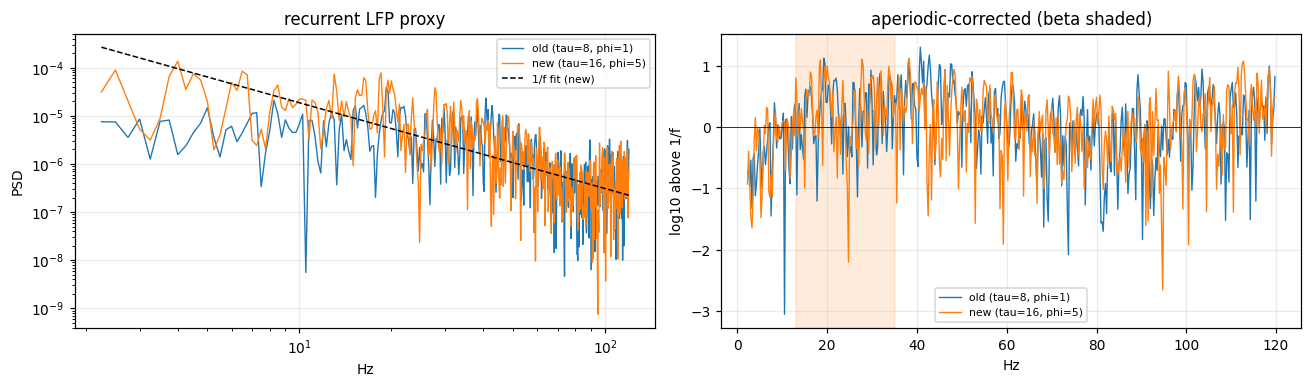

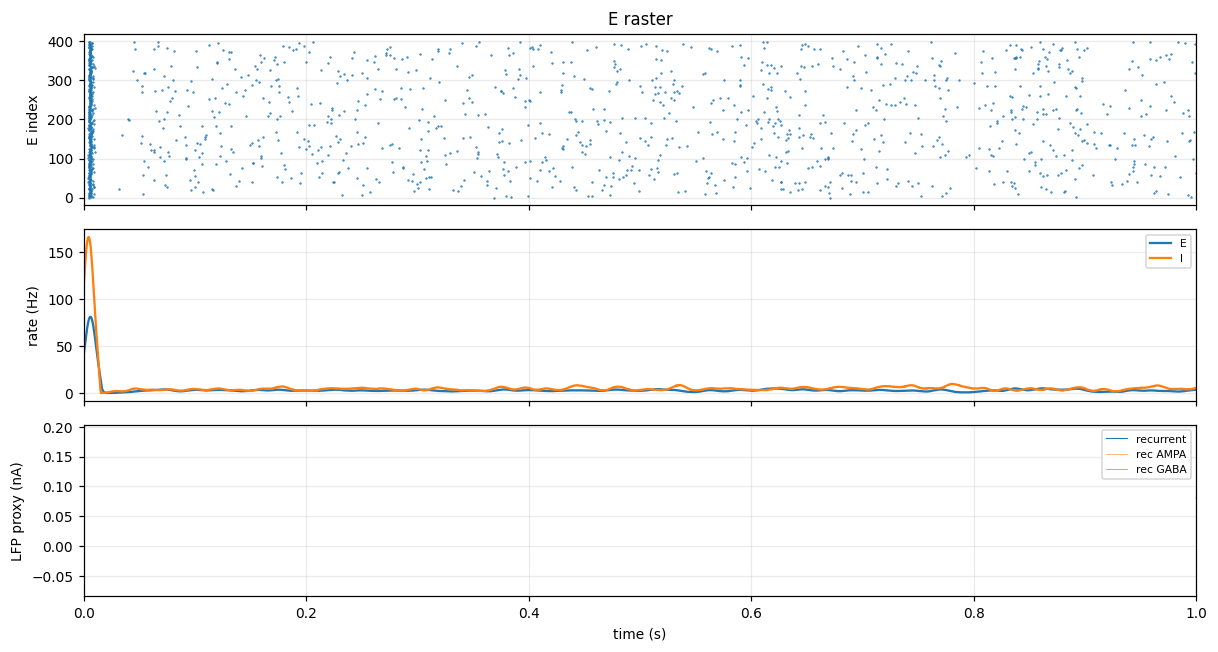

In [6]:
def plot_compare(results, labels, band=(13, 35)):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    for (f, pxx, resid), lab in zip(results, labels):
        k = (f > 2) & (f < 120)
        ax[0].loglog(f[k], pxx[k], lw=0.9, label=lab)
        ax[1].plot(f[k], resid[k], lw=0.9, label=lab)
    _, slope, offset = aperiodic_residual(results[-1][0], results[-1][1])
    k = (results[-1][0] > 2) & (results[-1][0] < 120)
    ax[0].loglog(results[-1][0][k],
                 10**(slope*np.log10(results[-1][0][k]) + offset),
                 'k--', lw=1, label='1/f fit (new)')
    ax[0].set(xlabel='Hz', ylabel='PSD', title='recurrent LFP proxy')
    ax[1].axhline(0, c='k', lw=0.5)
    ax[1].axvspan(*band, color='C1', alpha=0.15)
    ax[1].set(xlabel='Hz', ylabel='log10 above 1/f',
              title='aperiodic-corrected (beta shaded)')
    ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
    plt.tight_layout(); plt.show()


def plot_network(n, lf, tmax=1.0):
    fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
    st, si = np.asarray(n['SP_E'].t/second), np.asarray(n['SP_E'].i)
    m = st < tmax
    ax[0].plot(st[m], si[m], '.', ms=1.0)
    ax[0].set(ylabel='E index', title='E raster')
    ax[1].plot(n['RATE_E'].t/second,
               n['RATE_E'].smooth_rate(window='gaussian', width=5*ms)/Hz, label='E')
    ax[1].plot(n['RATE_I'].t/second,
               n['RATE_I'].smooth_rate(window='gaussian', width=5*ms)/Hz, label='I')
    ax[1].set(ylabel='rate (Hz)'); ax[1].legend(fontsize=7)
    ax[2].plot(lf['t'], lf['recurrent'], lw=0.7, label='recurrent')
    ax[2].plot(lf['t'], lf['exc'], lw=0.5, alpha=0.7, label='rec AMPA')
    ax[2].plot(lf['t'], lf['inh'], lw=0.5, alpha=0.7, label='rec GABA')
    ax[2].set(ylabel='LFP proxy (nA)', xlabel='time (s)', xlim=(0, tmax))
    ax[2].legend(fontsize=7)
    plt.tight_layout(); plt.show()


plot_compare([(f_old, p_old, r_old), (f_new, p_new, r_new)],
             ['old (tau=8, phi=1)', 'new (tau=16, phi=5)'])
plot_network(new, lf_new)

## 4. Seed-averaged PSD — change 3

With 400 cells at `P = 0.1` each neuron gets ~40 recurrent inputs, so finite-size fluctuations
are large and single-seed prominence is unreliable. Average the PSDs first, then fit the
aperiodic component to the average — not the other way round.

In [7]:
def mean_psd(seeds=SEEDS, duration=None, which='recurrent', band=(13, 35), **kw):
    psds, rate_E, rate_I = [], [], []
    f = None
    for s in seeds:
        n = run_net(build_net(seed_val=s, **kw), duration)
        lf = lfp_proxies(n)
        f, pxx, _ = spectrum(lf[which])
        psds.append(pxx)
        r = rates(n, duration)
        rate_E.append(r['E']); rate_I.append(r['I'])
    pxx = np.mean(psds, axis=0)
    resid, slope, offset = aperiodic_residual(f, pxx)
    fpk, prom = report_bump(f, resid, band)
    return dict(f=f, psd=pxx, resid=resid, slope=slope, offset=offset,
                bump_hz=fpk, prominence=prom,
                rate_E=float(np.mean(rate_E)), rate_I=float(np.mean(rate_I)),
                n_seeds=len(seeds))


avg = mean_psd()
print(f"averaged over {avg['n_seeds']} seeds: E {avg['rate_E']:.2f} Hz, "
      f"I {avg['rate_I']:.2f} Hz, bump {avg['bump_hz']:.1f} Hz "
      f"x{avg['prominence']:.2f}, slope {avg['slope']:.2f}")

averaged over 1 seeds: E 2.94 Hz, I 5.12 Hz, bump 24.2 Hz x10.14, slope -1.73


### 4.1 Drive balance — change 4

Set the firing rates before touching frequency or gain. Target E 3–8 Hz, I 15–30 Hz, both with
CV above ~0.8. `I_tonic_I` moves I strongly and drags E down with it; `I_tonic_E` pushes back.
Keep `w_IE`/`P_IE` at 3.0/0.10 here, or the inhibition will swamp E before the rates are right.

In [8]:
DRIVE_GRID = [(0.35, 0.70), (0.60, 0.70)] if QUICK else \
             [(0.35, 0.50), (0.35, 0.70), (0.50, 0.90), (0.70, 1.10), (0.90, 1.40)]

for ie, ii in DRIVE_GRID:
    n = run_net(build_net(I_tonic_E=ie, I_tonic_I=ii))
    print(f'I_tonic_E={ie:4.2f} I_tonic_I={ii:4.2f} -> ', end='')
    summarise(n)

I_tonic_E=0.35 I_tonic_I=0.70 -> E  2.99 Hz (CV 0.91) | I  4.84 Hz (CV 1.15) | bump  27.8 Hz x12.73 | 1/f slope -1.78


I_tonic_E=0.60 I_tonic_I=0.70 -> E  5.81 Hz (CV 1.01) | I  6.34 Hz (CV 1.14) | bump  29.8 Hz x18.84 | 1/f slope -1.72


## 5. `τ_GABA` sweep — change 5

Sweep this alone and first: it is the strongest lever on peak *frequency* and barely touches
firing rates. Loop half-period is roughly `delay_EI + delay_IE + τ_GABA`, so expect the peak
near `1/(2·(2 + 6 + τ))`. Target 20–25 Hz.

tau_GABA= 10.0 ms  bump= 34.8 Hz  x14.02  E= 3.64  I= 6.00  slope=-1.42


tau_GABA= 16.0 ms  bump= 24.2 Hz  x10.14  E= 2.94  I= 5.12  slope=-1.73


tau_GABA= 24.0 ms  bump= 33.8 Hz  x12.22  E= 2.43  I= 4.34  slope=-1.91


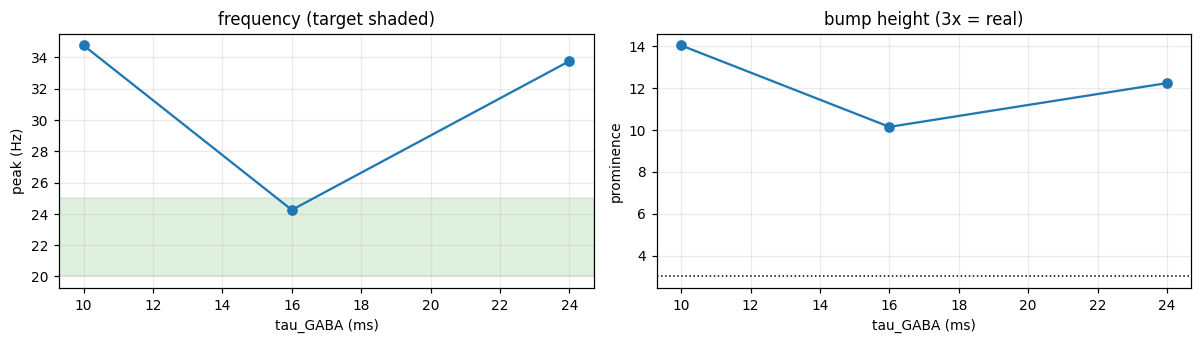

In [9]:
TAU_GRID = [10., 16., 24.] if QUICK else [8., 10., 13., 16., 20., 24., 30.]

rows = []
for tg in TAU_GRID:
    a = mean_psd(tau_gaba_decay=tg)
    rows.append(dict(tau=tg, **{k: a[k] for k in
                ('bump_hz', 'prominence', 'rate_E', 'rate_I', 'slope')}))
    print(f"tau_GABA={tg:5.1f} ms  bump={a['bump_hz']:5.1f} Hz  "
          f"x{a['prominence']:4.2f}  E={a['rate_E']:5.2f}  I={a['rate_I']:5.2f}  "
          f"slope={a['slope']:5.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
tau = [r['tau'] for r in rows]
ax[0].plot(tau, [r['bump_hz'] for r in rows], 'o-')
ax[0].axhspan(20, 25, color='C2', alpha=0.15)
ax[0].set(xlabel='tau_GABA (ms)', ylabel='peak (Hz)', title='frequency (target shaded)')
ax[1].plot(tau, [r['prominence'] for r in rows], 'o-')
ax[1].axhline(3, c='k', ls=':', lw=1)
ax[1].set(xlabel='tau_GABA (ms)', ylabel='prominence', title='bump height (3x = real)')
plt.tight_layout(); plt.show()

## 6. Loop-gain sweep — change 6

Once the peak sits near 22 Hz, raise gain until prominence reaches 3–5×. Watch `cv_E`: if it
falls below ~0.5 the network has gone clock-like and the peak is an artifact of
over-synchronisation, not sparse synchrony. Fix `tau_gaba_decay` to whichever value §5 chose
before running this.

In [10]:
TAU_BEST = min(rows, key=lambda r: abs(r['bump_hz'] - 22.0))['tau']
print(f'using tau_GABA = {TAU_BEST} ms from the sweep above\n')

GAIN_GRID = [(3., 0.10), (5., 0.10)] if QUICK else \
            [(3., 0.10), (4., 0.10), (5., 0.15), (6., 0.15), (8., 0.20)]

for w, p in GAIN_GRID:
    n = run_net(build_net(tau_gaba_decay=TAU_BEST, w_IE=w, P_IE=p))
    print(f'w_IE={w:5.1f} P_IE={p:4.2f} -> ', end='')
    summarise(n)

using tau_GABA = 16.0 ms from the sweep above



w_IE=  3.0 P_IE=0.10 -> E  2.99 Hz (CV 0.91) | I  4.84 Hz (CV 1.15) | bump  27.8 Hz x12.73 | 1/f slope -1.78


w_IE=  5.0 P_IE=0.10 -> E  2.61 Hz (CV 0.91) | I  4.78 Hz (CV 1.15) | bump  16.5 Hz x16.03 | 1/f slope -1.83


## 7. Notes

**Measured starting point.** At `tau_gaba_decay=16`, `delay_I=(4,8)`, `w_IE=3`, `P_IE=0.10`,
`I_tonic_I=0.70` the network gives a beta bump near 25 Hz with prominence around 5–12x and a 1/f
slope near −2, with E still low. Getting E into 3–8 Hz while holding I at 15–30 is the remaining
work, and §4.1 is where to do it.

**Acceptance criteria.** E 3–8 Hz, I 15–30 Hz, `cv_E` and `cv_I` above ~0.8, beta peak 20–25 Hz
with prominence 3–5×, 1/f slope between −1 and −2. If prominence is high but CV is low, back off
the gain — the peak is coming from the wrong place.

**Don't chase theta yet.** On a 1/f background, "lots of theta, less alpha, then a beta bump" is
what a single beta resonance on a 1/f slope already looks like: the theta excess is the slope,
not an oscillator. Check the aperiodic-corrected residual in §3.1 — if theta shows no positive
residual, one resonance is all you need and this network is structurally sufficient. If theta
*does* bump above the fit, one E–I loop cannot produce both, and the cheapest second timescale
is a spike-triggered adaptation current on the E cells (`tau_w` 100–200 ms), not a second
interneuron class.

**Prominence depends on network size.** The synchronous component of the LFP proxy scales
differently from the independent component, so a gain that gives a 3× bump at NE = 400 will not
at NE = 4000. Fix `NE`/`NI` before optimising gain, or normalise `w_IE` by √N as well as the
`800/NE` scaling already applied to the conductances.

**If the search gets wider than this.** Reduce to four control parameters (total drive to E, the
E/I drive ratio, loop gain, `τ_GABA`), target rates with short 5 s runs, then optimise the
spectral terms with 40 s runs — rates and frequency are nearly separable, since drive sets rates
and `τ_GABA` sets frequency. A `specparam`/FOOOF fit turns the visual target into 4–6 numbers
and makes Nelder-Mead or CMA-ES usable.